# 14 · Capstone: a GenAI system for a statistician

**Question.** Can we build a small assistant whose claims can be reproduced and checked?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/14-capstone.ipynb)

This chapter completes a worked project: a bounded simulation assistant that investigates the coverage of an approximate confidence interval. It receives a structured request, runs an approved simulation, and returns an evidence-based report with Monte Carlo uncertainty. We compare it with a nominal-coverage baseline on scenarios excluded from development.

The executable assistant uses deterministic planning and report templates. It is a baseline and execution core for a GenAI system, not a hidden LLM call. A language model can later translate a user's request into the schema or explain the returned evidence, while the numerical claims remain controlled by the tested tool. This separation makes the project runnable without an API key and makes the contribution of an LLM an explicit ablation.

**Prerequisites:** Chapters 2, 11–13. **Outcomes:** write a scoped project specification; implement the complete evidence path; evaluate on held-out scenarios; report uncertainty and failures; define a meaningful generative extension.

## 14.1 · Specify the user, target, and loss

The user is a statistics instructor preparing a simulation lesson. The question is: for iid samples from a specified distribution, how often does

$$
\bar X\pm1.96\frac{S}{\sqrt n}
$$

contain the population mean? This is an approximate normal interval using an estimated standard error. It is not the exact Student-t interval for normal data. Its nominal 95% label should not be confused with its actual finite-sample coverage.

Our task population consists of predefined combinations of distribution and sample size. The main evaluation loss is absolute error in estimated coverage relative to an independently simulated high-precision reference. We also report invalid-request handling and computational budget. We do not claim validity for dependent observations, arbitrary distributions, or automatic real-data inference.

## 14.2 · Create development and evaluation scenarios first

Development uses sample size 30 under normal and exponential distributions. We fix the simulation budget at 500 repetitions and the report format before examining the evaluation scenarios. Evaluation uses sample sizes 12, 60, and 120. These are held-out scenario settings within known distribution families, not unseen families.

In [1]:
import json
import platform
from dataclasses import dataclass, asdict
import numpy as np
import matplotlib.pyplot as plt

DEVELOPMENT = [('normal', 30), ('exponential', 30)]
EVALUATION = [(family, n) for family in ['normal', 'exponential'] for n in [12, 60, 120]]
BUDGET = 500

@dataclass(frozen=True)
class Request:
    family: str
    n: int
    repetitions: int = BUDGET
    seed: int = 1400

def validate(request):
    if request.family not in ('normal', 'exponential'):
        raise ValueError('Only normal and exponential families are supported')
    if type(request.n) is not int or not 5 <= request.n <= 500:
        raise ValueError('Sample size must be an integer between 5 and 500')
    if type(request.repetitions) is not int or not 100 <= request.repetitions <= 5000:
        raise ValueError('Repetitions must be between 100 and 5000')
    if type(request.seed) is not int or request.seed < 0:
        raise ValueError('Seed must be a nonnegative integer')

print('Development:', DEVELOPMENT)
print('Locked evaluation:', EVALUATION)

Development: [('normal', 30), ('exponential', 30)]
Locked evaluation: [('normal', 12), ('normal', 60), ('normal', 120), ('exponential', 12), ('exponential', 60), ('exponential', 120)]


The schema prevents a generated plan from choosing an unbounded computation or quietly switching distributions. If a user asks about a family outside this scope, the correct response is to explain the limitation or extend and validate the tool, not silently substitute a familiar family.

## 14.3 · Implement the statistical tool

For each replicate, simulate a sample, calculate its interval, and record a coverage indicator. A Wilson interval summarizes uncertainty in the Monte Carlo coverage proportion. This is an interval for the simulation's coverage probability, not an interval for the mean in one of the simulated samples.

In [2]:
def coverage_indicators(family, n, repetitions, seed):
    rng = np.random.default_rng(seed)
    if family == 'normal':
        values, population_mean = rng.normal(size=(repetitions, n)), 0.0
    elif family == 'exponential':
        values, population_mean = rng.exponential(size=(repetitions, n)), 1.0
    else:
        raise ValueError('Unsupported family')
    means = values.mean(1)
    halfwidth = 1.96 * values.std(1, ddof=1) / np.sqrt(n)
    return np.abs(means-population_mean) <= halfwidth

def wilson_interval(successes, total, z=1.96):
    p = successes / total
    denominator = 1 + z*z/total
    center = (p + z*z/(2*total)) / denominator
    radius = z*np.sqrt(p*(1-p)/total + z*z/(4*total*total)) / denominator
    return float(center-radius), float(center+radius)

def simulation_tool(request):
    validate(request)
    covered = coverage_indicators(request.family, request.n,
                                  request.repetitions, request.seed)
    successes = int(covered.sum())
    low, high = wilson_interval(successes, request.repetitions)
    return {'request': asdict(request), 'covered': successes,
            'estimate': float(covered.mean()), 'mc_interval': [low, high],
            'method': 'mean +/- 1.96 * sample_sd / sqrt(n)'}

def report(result):
    r = result['request']
    low, high = result['mc_interval']
    return (f"For iid {r['family']} samples with n={r['n']}, the simulated coverage "
            f"was {result['estimate']:.3f} in {r['repetitions']} repetitions. "
            f"The approximate 95% Monte Carlo interval is [{low:.3f}, {high:.3f}]. "
            'This describes the specified simulation and interval procedure.')

example = simulation_tool(Request('exponential', 30))
print(report(example))
print(json.dumps(example, indent=2))

For iid exponential samples with n=30, the simulated coverage was 0.878 in 500 repetitions. The approximate 95% Monte Carlo interval is [0.846, 0.904]. This describes the specified simulation and interval procedure.
{
  "request": {
    "family": "exponential",
    "n": 30,
    "repetitions": 500,
    "seed": 1400
  },
  "covered": 439,
  "estimate": 0.878,
  "mc_interval": [
    0.8463946427702861,
    0.9038411456203509
  ],
  "method": "mean +/- 1.96 * sample_sd / sqrt(n)"
}


The report only inserts numerical results returned by the tool. It does not convert an approximate simulation finding into a universal coverage theorem. A language-model report should be checked against these same numeric fields and should preserve the distribution, sample size, repetition count, and method.

## 14.4 · Establish implementation checks

In [3]:
again = simulation_tool(Request('exponential', 30))
assert again == example
assert 0 <= example['estimate'] <= 1
assert 0 <= example['mc_interval'][0] <= example['mc_interval'][1] <= 1

invalid_requests = [Request('unknown', 30), Request('normal', 2),
                    Request('normal', 30, repetitions=1000000)]
for request in invalid_requests:
    try:
        simulation_tool(request)
    except ValueError as error:
        print('Rejected request:', str(error))
    else:
        raise AssertionError('An invalid request was accepted')

Rejected request: Only normal and exponential families are supported
Rejected request: Sample size must be an integer between 5 and 500
Rejected request: Repetitions must be between 100 and 5000


These checks verify reproducibility, basic invariants, and the resource boundary. They do not prove the statistical formula correct. Review the formula separately: sample standard deviation uses `ddof=1`; the target mean is zero for the standard normal and one for the unit-rate exponential; coverage uses both interval endpoints.

## 14.5 · Evaluate the locked scenarios

The baseline always predicts coverage 0.95, interpreting the nominal label literally. The tool estimates coverage from 500 fresh replicates. An independent 20,000-replicate run supplies a more precise reference for this teaching comparison. The reference is still Monte Carlo, not an exact truth oracle.

normal      n= 12: estimate=0.938, reference=0.924, reference MC SE=0.0019
normal      n= 60: estimate=0.944, reference=0.946, reference MC SE=0.0016
normal      n=120: estimate=0.958, reference=0.951, reference MC SE=0.0015
exponential n= 12: estimate=0.862, reference=0.878, reference MC SE=0.0023
exponential n= 60: estimate=0.938, reference=0.932, reference MC SE=0.0018
exponential n=120: estimate=0.958, reference=0.944, reference MC SE=0.0016
Mean absolute error: nominal / tool 0.021 0.01


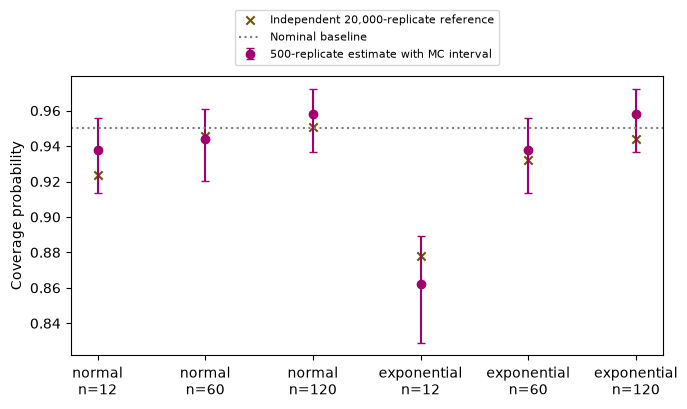

In [4]:
rows = []
for i, (family, n) in enumerate(EVALUATION):
    result = simulation_tool(Request(family, n, seed=1500+i))
    reference_indicators = coverage_indicators(family, n, 20000, seed=9000+i)
    reference = float(reference_indicators.mean())
    reference_se = np.sqrt(reference*(1-reference)/len(reference_indicators))
    rows.append({'family': family, 'n': n, 'nominal': 0.95,
                 'estimated': result['estimate'], 'reference': reference,
                 'reference_mc_se': reference_se,
                 'low': result['mc_interval'][0], 'high': result['mc_interval'][1]})
    print(f"{family:11s} n={n:3d}: estimate={result['estimate']:.3f}, "
          f"reference={reference:.3f}, reference MC SE={reference_se:.4f}")

baseline_error = np.array([abs(r['nominal']-r['reference']) for r in rows])
tool_error = np.array([abs(r['estimated']-r['reference']) for r in rows])
print('Mean absolute error: nominal / tool', baseline_error.mean().round(3),
      tool_error.mean().round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(rows))
estimated = np.array([r['estimated'] for r in rows])
error_bars = np.array([[r['estimated']-r['low'] for r in rows],
                       [r['high']-r['estimated'] for r in rows]])
ax.errorbar(x, estimated, yerr=error_bars, fmt='o', color='#a2006e',
            capsize=3, label='500-replicate estimate with MC interval')
ax.scatter(x, [r['reference'] for r in rows], marker='x', color='#705600',
           label='Independent 20,000-replicate reference')
ax.axhline(0.95, ls=':', color='gray', label='Nominal baseline')
ax.set(xticks=x, xticklabels=[f"{r['family']}\nn={r['n']}" for r in rows],
       ylabel='Coverage probability')
ax.legend(fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

There are only six fixed scenarios. Do not attach an iid-task confidence interval to their average error without defining how they were sampled from a task population. The per-scenario Monte Carlo intervals answer a different question: uncertainty from the finite simulation budget conditional on that scenario.

The expected pattern is that asymmetry and small sample size can make nominal coverage misleading. Interpret the displayed results rather than asserting a guaranteed ranking. The simulation tool can be noisier than the baseline in a scenario whose actual coverage happens to be close to 0.95.

## 14.6 · Add a generative component as an ablation

A bounded LLM extension can translate a natural-language question into `Request` and produce a narrative from the resulting JSON. Evaluate these stages separately:

1. **Plan accuracy:** did the proposed family, sample size, and method match the request?
2. **Execution validity:** did schema and budget validation pass, and was the requested tool run?
3. **Numerical faithfulness:** do all reported numbers agree with the tool output at the declared rounding?
4. **Interpretation:** does the text distinguish nominal coverage, simulated coverage, and Monte Carlo uncertainty?
5. **Abstention:** does the system identify unsupported distributions or requests?

Compare the deterministic report with an LLM report from identical evidence, and compare direct LLM answers with tool-assisted answers on the same questions. Record the model identifier and date, prompt, generation settings, raw response, parsed request, tool result, and scoring rubric. Do not give the LLM reference answers in its prompt or allow it to choose the scoring rule after seeing outcomes.

## 14.7 · Produce a reproducibility manifest and report

In [5]:
manifest = {
    'project': 'Coverage simulation assistant',
    'data': 'Synthetic iid samples generated inside this notebook',
    'development_scenarios': DEVELOPMENT,
    'evaluation_scenarios': EVALUATION,
    'assistant_repetitions': BUDGET,
    'reference_repetitions': 20000,
    'evaluation_seeds': list(range(1500, 1500+len(EVALUATION))),
    'reference_seeds': list(range(9000, 9000+len(EVALUATION))),
    'python': platform.python_version(),
    'numpy': np.__version__,
    'scope': 'Normal/exponential iid data; approximate z intervals with estimated SD',
}
print(json.dumps(manifest, indent=2))
print('family,n,nominal,estimated,reference')
for r in rows:
    print(f"{r['family']},{r['n']},{r['nominal']:.4f},{r['estimated']:.4f},{r['reference']:.4f}")

{
  "project": "Coverage simulation assistant",
  "data": "Synthetic iid samples generated inside this notebook",
  "development_scenarios": [
    [
      "normal",
      30
    ],
    [
      "exponential",
      30
    ]
  ],
  "evaluation_scenarios": [
    [
      "normal",
      12
    ],
    [
      "normal",
      60
    ],
    [
      "normal",
      120
    ],
    [
      "exponential",
      12
    ],
    [
      "exponential",
      60
    ],
    [
      "exponential",
      120
    ]
  ],
  "assistant_repetitions": 500,
  "reference_repetitions": 20000,
  "evaluation_seeds": [
    1500,
    1501,
    1502,
    1503,
    1504,
    1505
  ],
  "reference_seeds": [
    9000,
    9001,
    9002,
    9003,
    9004,
    9005
  ],
  "python": "3.13.16",
  "numpy": "2.5.3",
  "scope": "Normal/exponential iid data; approximate z intervals with estimated SD"
}
family,n,nominal,estimated,reference
normal,12,0.9500,0.9380,0.9237
normal,60,0.9500,0.9440,0.9458
normal,120,0.9500,0.9580,0

A final project report should state the question and task population, describe the baseline and extension, document splits and seeds, show results with uncertainty and failures, and explain limitations in plain language. Include the executable notebook and environment information so another reader can reproduce the evidence.

For this worked example, a supported conclusion is narrow: the assistant executes a bounded coverage simulation and reports its numerical output faithfully. Any advantage over the nominal baseline is conditional on the evaluated scenarios and simulation budget. The lab has not demonstrated general natural-language planning or safe autonomous statistical analysis.

## 14.8 · Exercises and worked solutions

1. **Monte Carlo budget:** how does standard error scale with repetitions? **Solution:** for independent coverage indicators, it is $\sqrt{p(1-p)/R}$. Quadrupling repetitions approximately halves it; it does not fix bias from using the wrong sampling distribution or interval formula.
2. **Two intervals:** distinguish the simulated confidence interval from the reported Monte Carlo interval. **Solution:** the first targets a population mean in one dataset; the second targets the coverage probability of that procedure under a specified simulator.
3. **New scenario:** add dependent observations. **Solution:** update the schema, data generator, target assumptions, and evaluation suite explicitly. Keeping an iid standard-error formula may lead to poor coverage; that is a substantive finding, not merely a software bug.
4. **Ablation:** what does removing the simulation tool test? **Solution:** it tests whether answers produced without numerical evidence are as accurate on the fixed coverage tasks. It does not isolate an LLM architecture effect unless model, prompts, and other resources are controlled.
5. **Reporting:** why not say “the assistant guarantees 95% coverage”? **Solution:** it estimates coverage of a specified approximate procedure with Monte Carlo uncertainty. Neither the numerical simulation nor a fluent report supplies a universal theorem.

## 14.9 · Choose your own extension

Three natural extensions are a citation-grounded explanation assistant using Chapter 10's notes, a more flexible simulation planner using Chapter 12's dispatcher, or a calibrated answer/abstention system using Chapter 11. Choose one change, specify how it should help, and evaluate it against the completed baseline before adding more components.

A finished project is one you can explain, reproduce, evaluate, and teach. Its scope can be small while its evidence is rigorous.